# CHURNSHIELD-AGENT

La metodología empleada para este proyecto es CRISP-ML(Q), el cual describe 6 fases:

- Business and Data Understanding 
- Data Engineering (Data Preparation)
- Machine Learning Model Engineering
- Quality Assurance for Machine Learning Applications
- Deployment
- Monitoring and Maintenance.

Este notebook pretende abarcar las dos primeras fases: Business and Data Understanding y Data Engineering.

## Lógica de negocio y entendimiento del dataset

La pérdida de clientes (en adelante, Churn) es uno de los mayores retos a los que se enfrentan las empresas de telecomunicaciones. El Churn se refiere a la situación en la que un cliente deja de utilizar los servicios de una empresa y se cambia a la competencia o cancela el servicio por completo.

Adquirir un nuevo cliente es significativamente más costoso que retener a uno existente. Por lo tanto, identificar a los clientes con probabilidades de darse de baja permite a las empresas tomar medidas preventivas, como ofrecer descuentos, mejorar la atención al cliente u ofrecer planes personalizados.

El dataset utilizado (IBM Telco Customer Churn) contiene información sobre los clientes de una empreza de telecomunicaciones, incluyendo datos demográficos, detalles de la cuenta, servicios a los que están suscritos, tipo de contrato, información de facturación y métodos de pago. Con este dataset, nuestro objetivo es construir un modelo de aprendizaje automático que pueda predecir con precisión si un cliente tiene probabilidades de darse de baja.

## Situación problema

Las empresas de telecomunicaciones pierden una cantidad significativa de ingresos cuando los clientes cancelan sus servicios. La empresa desea identificar a los clientes con alto riesgo de cancelar su servicio para poder implementar estrategias proactivas de retención. El objetivo comercial es reducir el Churn de clientes mediante la identificación de aquellos que tienen probabilidades de dejar la empresa.

El reto consiste en desarrollar un modelo predictivo que clasifique a los clientes en dos categorías:

- Churn = Yes
- Churn = No

El modelo debe identificar con precisión a los clientes con riesgo de baja utilizando información histórica de los clientes. La implementación adecuada del modelo debería ayudar a la empresa a:

- Mejorar la retención de clientes.
- Reducir la pérdida de ingresos.
- Aumentar la satisfacción del cliente.
- Diseñar campañas de retención personalizadas.
- Optimizar las iniciativas de mercadotecnia y atención al cliente.

## Problema de Machine Learning

El problema se trata de uno de **Aprendizaje Supervisado** porque el conjunto de datos contiene ejemplos etiquetados. Además, se trata de un problema de **clasificación binaria** dado que la variable objetivo (Churn) solo tiene tiene dos clases: "Sí" indica que el cliente dejará la compañía, mientras que "No" indica que el cliente continuará usando los servicios de la compañía.

El propósito del modelo es predecir si un cliente dejará los servicios de la compañía de acuerdo a las características disponibles.

# Cargar librerías

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el dataset

In [27]:
df_original = pd.read_excel('Telco_customer_churn.xlsx')

## Vista general del dataset

In [28]:
df_original.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [29]:
df_original.tail()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,...,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,NaN
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,...,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,NaN
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,...,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,NaN
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,...,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN
7042,3186-AJIEK,1,United States,California,Apple Valley,92308,"34.424926, -117.184503",34.424926,-117.184503,Male,...,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No,0,38,5097,NaN


In [30]:
df_original.shape

(7043, 33)

# Análisis del dataset

In [31]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [32]:
df_original.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [33]:
df_original.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='str')

In [34]:
df_original.dtypes

CustomerID               str
Count                  int64
Country                  str
State                    str
City                     str
Zip Code               int64
Lat Long                 str
Latitude             float64
Longitude            float64
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges         object
Churn Label              str
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason             str
dtype: object

Se observa que Total Charges tiene un tipo que no le corresponde. Dentro del dataset, esta columna contiene números, y no se está leyendo correctamente. Se corregirá esta columna a int, sin embargo, se creará una copia del dataframe original para trabajar de aquí en adelante (para no modificar el mismo).

In [35]:
df = df_original.copy()

In [36]:
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")

In [37]:
df.dtypes

CustomerID               str
Count                  int64
Country                  str
State                    str
City                     str
Zip Code               int64
Lat Long                 str
Latitude             float64
Longitude            float64
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges        float64
Churn Label              str
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason             str
dtype: object

# Limpieza del dataset

En esta sección se eliminan los registros duplicados (si es que hay) y además se anotan las variables que se ven desde ahora que no aportarán nada al modelo, sin embargo, estas no se eliminan del dataset

In [38]:
df.duplicated().sum()

np.int64(0)

Como no hay duplicados no se puede hacer más nada en esta parte

In [39]:
print(df.isnull().sum())

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges          11
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64


In [40]:
df = df.drop(columns=[
    'CustomerID',
    'Count',
    'Country',
    'Lat Long',
    'Churn Label',
    'Churn Score',
    'Churn Reason'
])

**Nota:** Estas variables no se eliminan del dataset original (`data/Telco_customer_churn.xlsx`) sino que quitan del dataframe usado en este cuadernillo y, por ende, los usados a partir de este. Las columnas se seguirán encontrando en el archivo de Excel de donde se extrajo el dataset.

Estas columnas se eliminan porque no aportan nada al modelo:

- CustomerID es un identificador para cada registro
- Count

# EDA

## Análisis de la variable objetivo

En nuestro dataset, la variable objetivo es **Churn Value** donde 1 es que el cliente se retiró/cambió a otro proveedor, mientras que 0 si no se ha retirado.

Primero se analizarán la proporción de clientes que se retiraron vs los que no

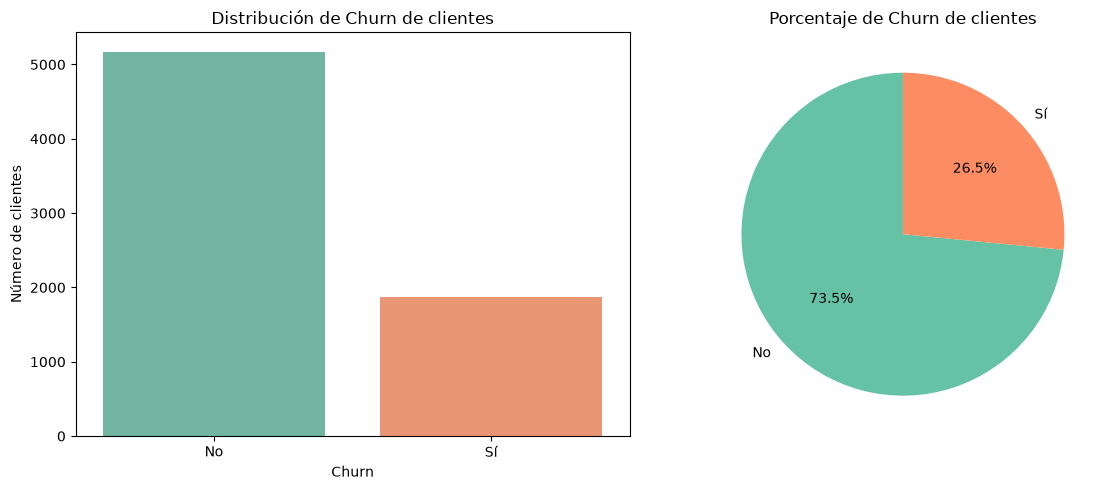

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# --- contar los valores
sns.countplot(
    x='Churn Value',
    hue='Churn Value',
    data=df,
    palette='Set2',
    legend=False,
    ax=ax[0]
)

ax[0].set_title("Distribución de Churn de clientes")
ax[0].set_xlabel("Churn")
ax[0].set_ylabel("Número de clientes")
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(['No', 'Sí'])

# --- piechart
df['Churn Value'].value_counts().plot(
    kind='pie',
    labels=['No', 'Sí'],
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette('Set2'),
    ax=ax[1]
)

ax[1].set_title("Porcentaje de Churn de clientes")
ax[1].set_ylabel("")

# Adjust spacing
plt.tight_layout()

# Show both plots
plt.show()

##  Análsis demográfico

Customer demographics provide insights into the characteristics of the customer base. In this section, we analyze the distribution of customers based on:

La demografía de los clientes puede mostrar caracteristicas de como son, por lo que revisaremos la distribución de los clientes basados en:

- Gender (sexo)
- Senior Citizen Status (condición de persona mayor, si es adulto mayor)
- Partner Status (estatus de socio, si está asociado)
- Dependents (Personas a cargo, si tiene personas a cargo)

Estas variables pueden ayudar a identificar factores que influencien el Churn de los clientes.

In [42]:
df.columns

Index(['State', 'City', 'Zip Code', 'Latitude', 'Longitude', 'Gender',
       'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Value',
       'CLTV'],
      dtype='str')

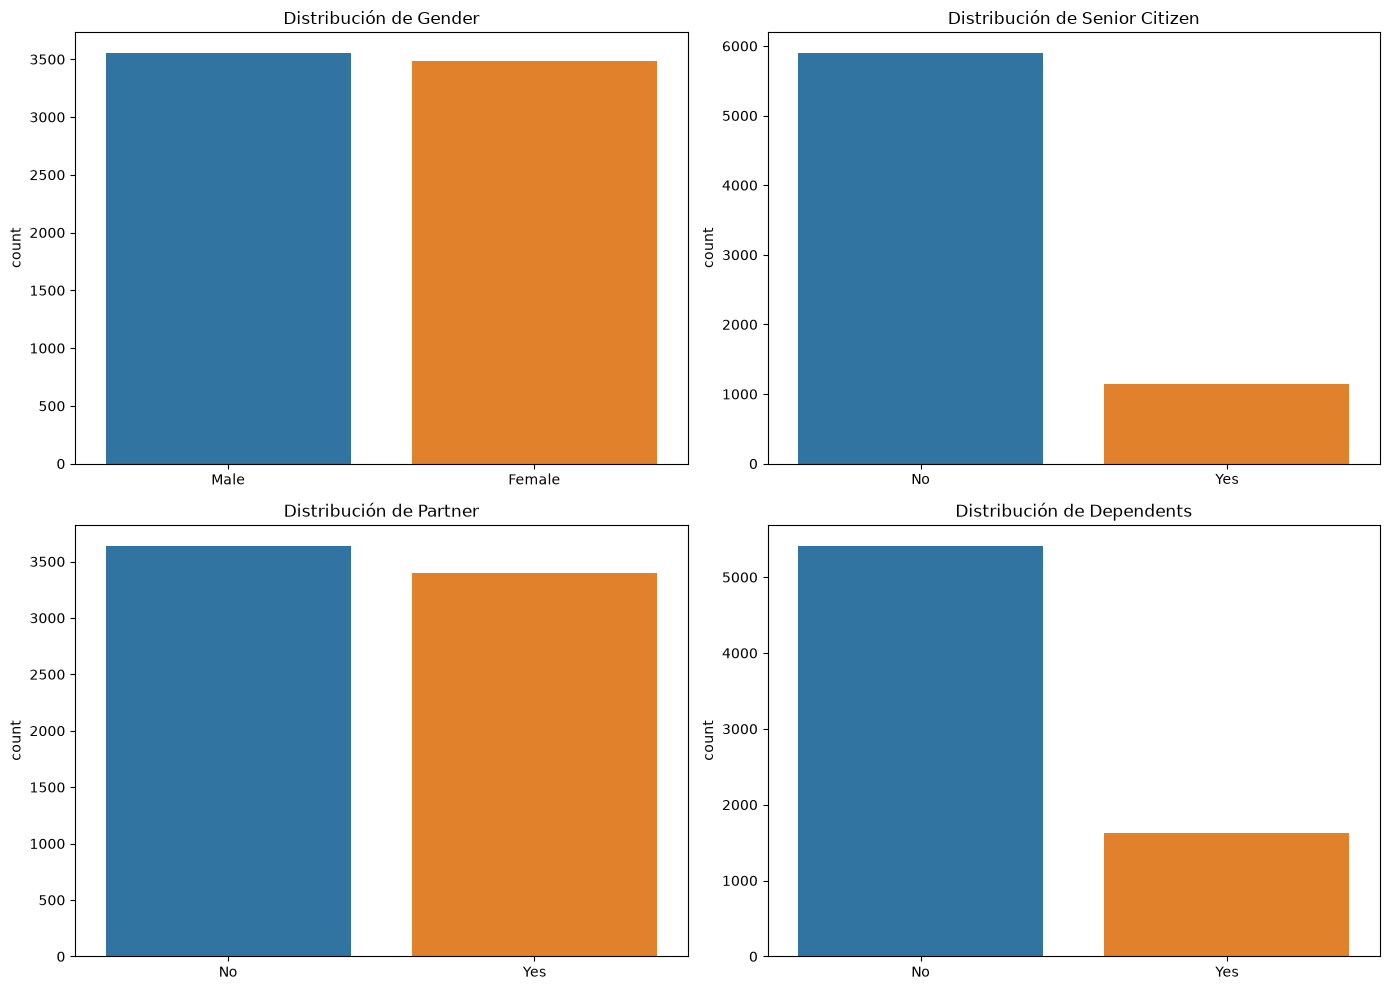

In [43]:
fig , axis = plt.subplots(2,2,figsize=(14,10))
#gender
sns.countplot(
    x='Gender',
    data=df,
    hue='Gender',
    ax=axis[0,0]
)
axis[0,0].set_title('Distribución de Gender')
axis[0,0].set_xlabel('')
axis[0,0].set_ylabel('count')

#senior citizen

sns.countplot(
    x='Senior Citizen',
    data=df,
    hue='Senior Citizen',
    ax=axis[0,1]
)
axis[0,1].set_title('Distribución de Senior Citizen')
axis[0,1].set_xlabel('')
axis[0,1].set_ylabel('count')

#partner
sns.countplot(
    x='Partner',
    data=df,
    hue='Partner',
    ax=axis[1,0]
)
axis[1,0].set_title('Distribución de Partner')
axis[1,0].set_xlabel('')
axis[1,0].set_ylabel('count')

#Dependents
sns.countplot(
    x='Dependents',
    data=df,
    hue='Dependents',
    ax=axis[1,1]
)
axis[1,1].set_title('Distribución de Dependents')
axis[1,1].set_xlabel('')
axis[1,1].set_ylabel('count')

plt.tight_layout()
plt.show()

## Análisis de servicios

En esta sección se analizan los servicios de telecomunicaciones a los que están suscritos los clientes. Comprender el uso de los servicios ayuda a identificar las preferencias de los clientes y la posible relación entre los servicios a los que están suscritos y la pérdida de clientes.

Se analizan las siguientes características relacionadas con el servicio:

- Phone Service (si tiene servicio telefónico)
- Internet Service (si tiene servicio de internet, y cuál tiene)
- Online Security (si tiene seguridad en línea)
- Tech Support (si cuenta con soporte al cliente)

Estas funciones brindan información valiosa sobre el comportamiento de los clientes y la adopción de los servicios.

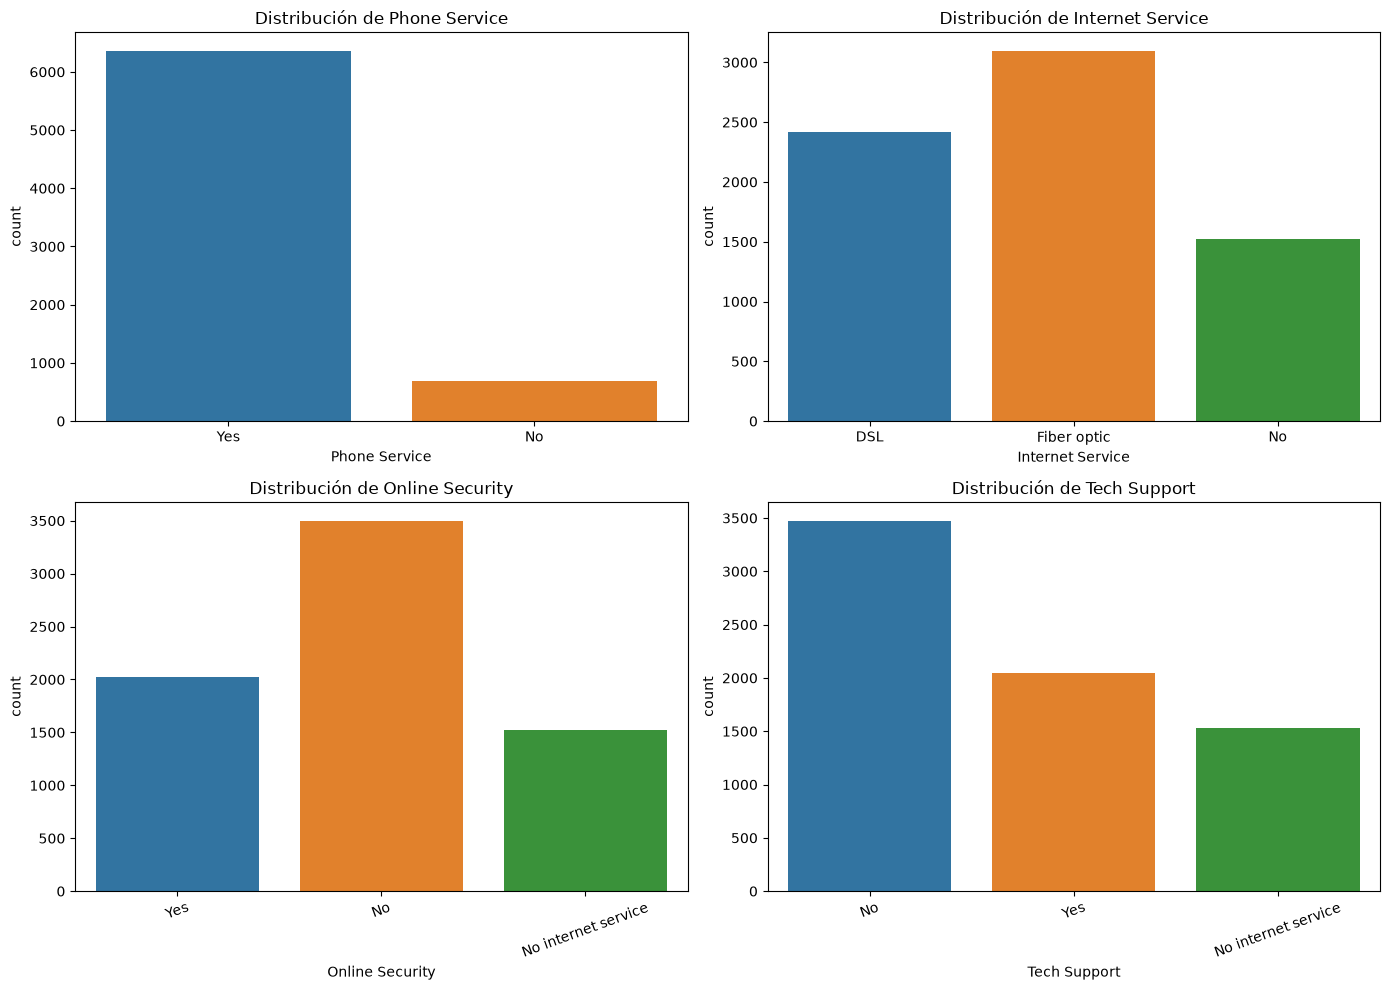

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Phone Service
sns.countplot(
    x='Phone Service',
    data=df,
    hue='Phone Service',
    ax=axes[0,0]
)
axes[0,0].set_title("Distribución de Phone Service")

# Internet Service
sns.countplot(
    x='Internet Service',
    data=df,
    hue='Internet Service',
    ax=axes[0,1]
)
axes[0,1].set_title("Distribución de Internet Service")

# Online Security
sns.countplot(
    x='Online Security',
    data=df,
    hue='Online Security',
    ax=axes[1,0]
)
axes[1,0].set_title("Distribución de Online Security")
axes[1,0].tick_params(axis='x', rotation=20)

# Tech Support
sns.countplot(
    x='Tech Support',
    data=df,
    hue='Tech Support',
    ax=axes[1,1]
)
axes[1,1].set_title("Distribución de Tech Support")
axes[1,1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

## Análisis de cuenta de los clientes

Estos datos ofrecen información sobre las preferencias de facturación y los tipos de contrato. Estas características desempeñan un papel importante para comprender el compromiso del cliente y su comportamiento de pago.

Se analizan las siguientes características:

- Contract Type (tipo de contrato)
- Payment Method (método de pago usado)
- Paperless Billing (facturación electrónica)

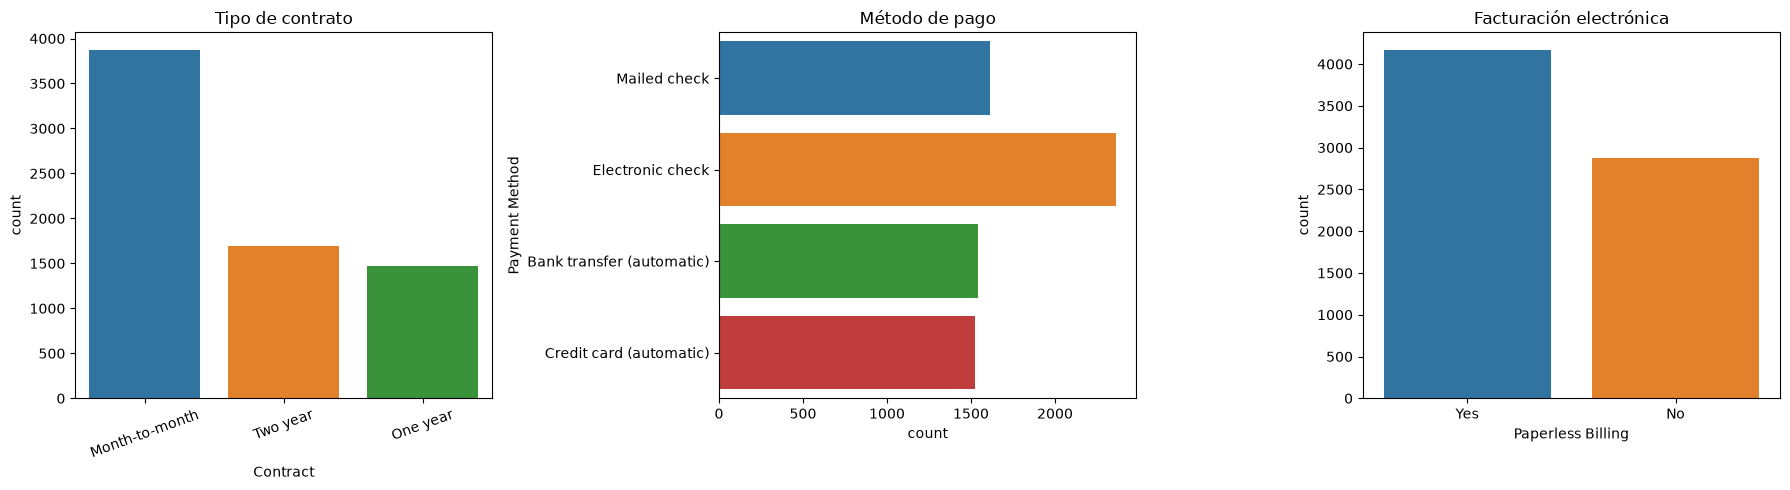

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Contract
sns.countplot(
    x='Contract',
    data=df,
    hue='Contract',
    ax=axes[0]
)
axes[0].set_title("Tipo de contrato")
axes[0].tick_params(axis='x', rotation=20)

# Payment Method
sns.countplot(
    y='Payment Method',
    data=df,
    hue='Payment Method',
    ax=axes[1]
)
axes[1].set_title("Método de pago")

# Paperless Billing
sns.countplot(
    x='Paperless Billing',
    data=df,
    hue='Paperless Billing',
    ax=axes[2]
)
axes[2].set_title("Facturación electrónica")

plt.tight_layout()
plt.show()

## Análisis de características numéricas

Las variables numéricas describen los patrones de uso y gasto de los clientes.

Se analizan las siguientes características numéricas:

- Tenure Months (meses de antigüedad)
- Monthly Charges (cuotas mensuales)
- Total Charges (total de cargos)

Los histogramas se utilizan para comprender la distribución de estas variables e identificar posibles valores atípicos o asimetrías.

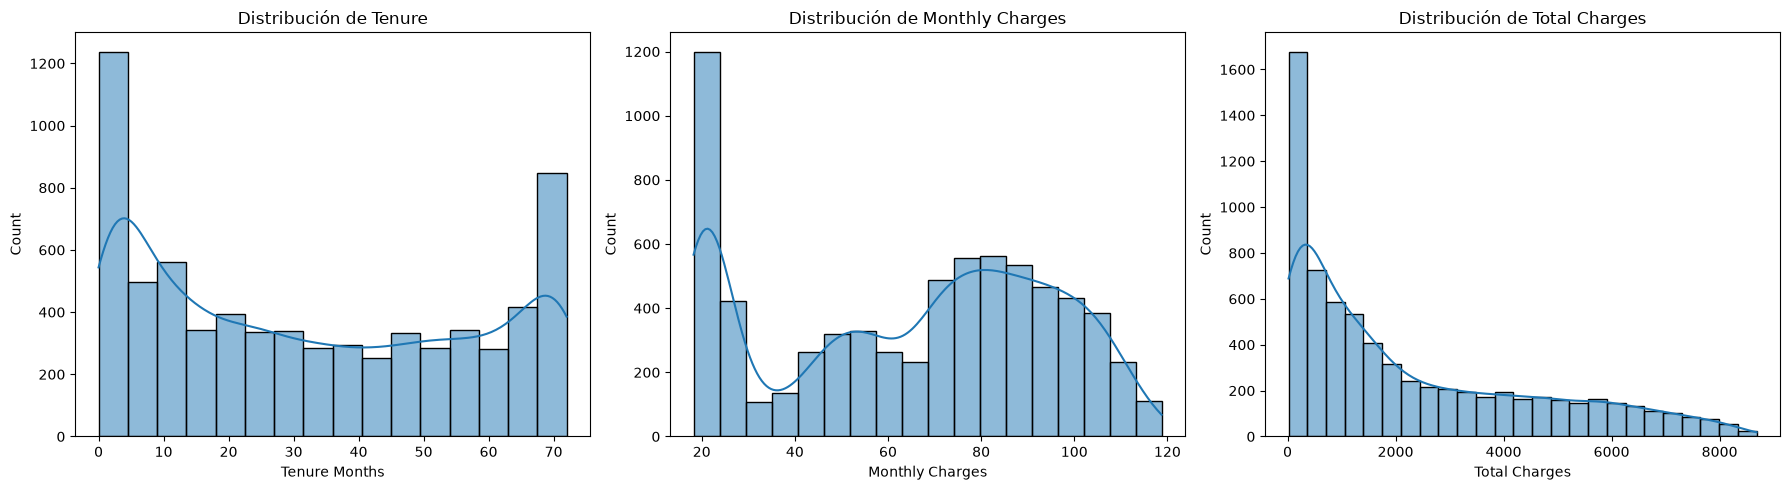

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Tenure
sns.histplot(
    df['Tenure Months'],
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribución de Tenure")

# Monthly Charges
sns.histplot(
    df['Monthly Charges'],
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Distribución de Monthly Charges")

# Total Charges
sns.histplot(
    df['Total Charges'],
    kde=True,
    ax=axes[2]
)
axes[2].set_title("Distribución de Total Charges")

plt.tight_layout()
plt.show()

## Relación entre las características de los clientes y Churn

El objetivo de este análisis es comprender cómo las características clave de los clientes influyen en el comportamiento de deserción.

Se analizan las siguientes relaciones:

- Contract Type vs Churn
- Internet Service vs Churn
- Monthly Charges vs Churn
- Tenure Months vs Churn

Este análisis ayuda a identificar los principales factores que contribuyen a la pérdida de clientes.

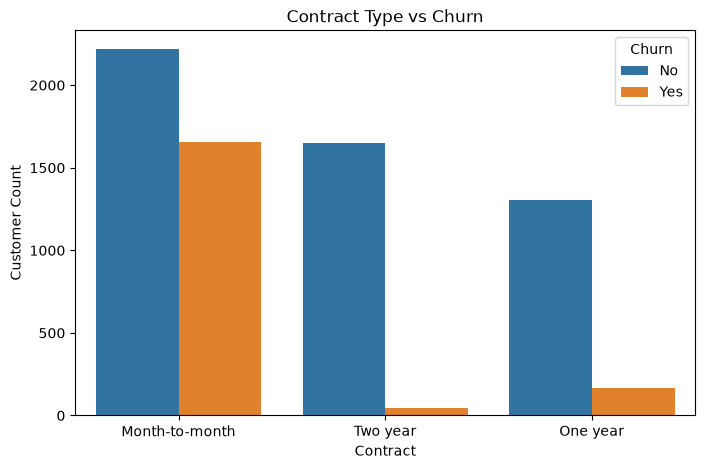

In [47]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Contract',
    hue='Churn Value',
    data=df
)

plt.title("Contract Type vs Churn")
plt.xlabel("Contract")
plt.ylabel("Customer Count")
plt.legend(title="Churn", labels=["No","Yes"])

plt.show()

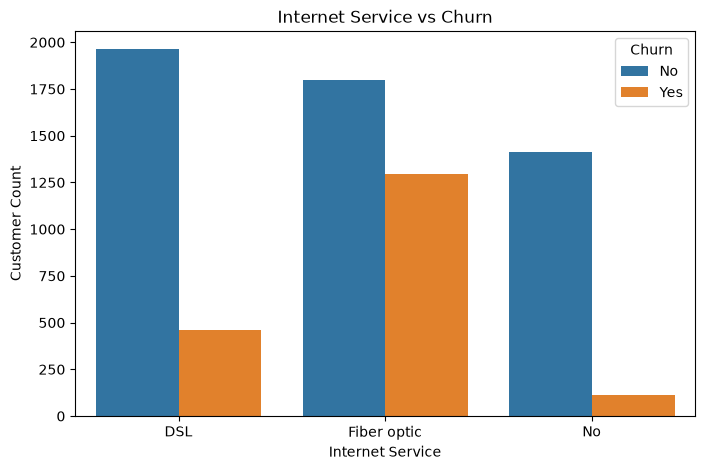

In [48]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Internet Service',
    hue='Churn Value',
    data=df
)

plt.title("Internet Service vs Churn")
plt.xlabel("Internet Service")
plt.ylabel("Customer Count")
plt.legend(title="Churn", labels=["No","Yes"])

plt.show()

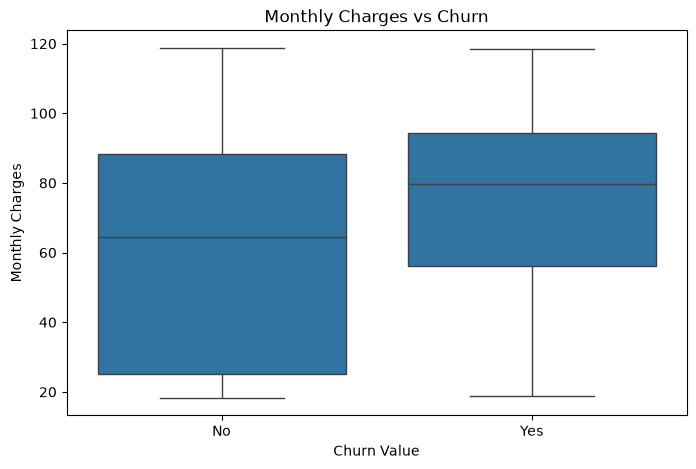

In [49]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Churn Value',
    y='Monthly Charges',
    data=df
)

plt.xticks([0,1],["No","Yes"])

plt.title("Monthly Charges vs Churn")

plt.show()

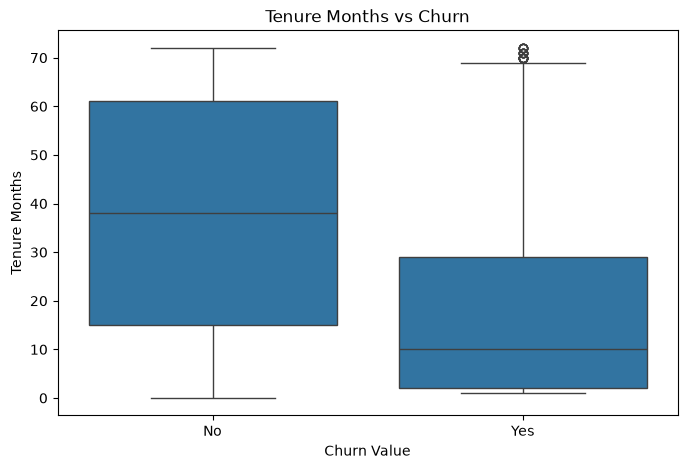

In [50]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Churn Value',
    y='Tenure Months',
    data=df
)

plt.xticks([0,1],["No","Yes"])

plt.title("Tenure Months vs Churn")

plt.show()

## Análisis de correlación

Un mapa de calor de correlación se utiliza para medir la intensidad y la dirección de las relaciones entre variables numéricas.

Los valores de correlación oscilan entre -1 y +1:

- +1 indica una fuerte correlación positiva.
- -1 indica una fuerte correlación negativa.
- 0 indica que no hay correlación lineal.

Esta visualización ayuda a identificar características numéricas altamente correlacionadas que podrían influir en la variable objetivo.

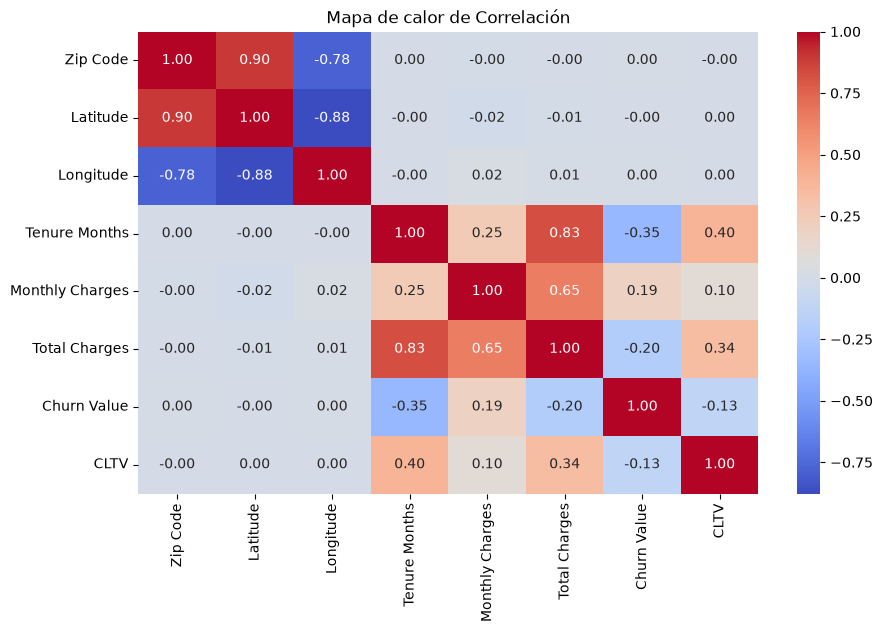

In [51]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])

plt.figure(figsize=(10,6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)

plt.title("Mapa de calor de Correlación")

plt.show()

# Validación de supuestos

De acuerdo a lo acordado anteriormente en el [planteamiento del problema](#problema-de-machine-learning), se utilizará el modelo de regresión logística para predecir el Churn de clientes. Por lo tanto, lo prudente es validar que se cumplen los supuestos de regresión logística para el dataset. Si algún supuesto falla de forma grave, las conclusiones de negocio y las probabilidades de churn podrían ser engañosas.

| # | Supuesto | Qué exige | Diagnóstico |
|---|----------|-----------|-------------|
| 1 | Observaciones independientes | Ningún registro influye en otro | Diseño del estudio, duplicados |
| 2 | Variable objetivo adecuada | Binaria 0/1 correcta | Inspección del objetivo |
| 3 | Linealidad del logit | Predictores lineales en los log-odds | Box-Tidwell + log-odds empíricos |
| 4 | Sin multicolinealidad grave | Predictores no fuertemente correlacionados | VIF + matriz de correlaciones |
| 5 | Tamaño muestral suficiente | Suficientes eventos por variable | Heurística EPV (≥ 10) |
| 6 | Sin atípicos influyentes | Ningún registro sesga el ajuste | Leverage, Cook, DFBETAS |